In [2]:
from itertools import product

import pandas as pd

import ipywidgets as widgets
from ipywidgets import interact

from IPython.display import display

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon, Rectangle

import random


# **Tarski table generator**
### Made by Adrian Usz

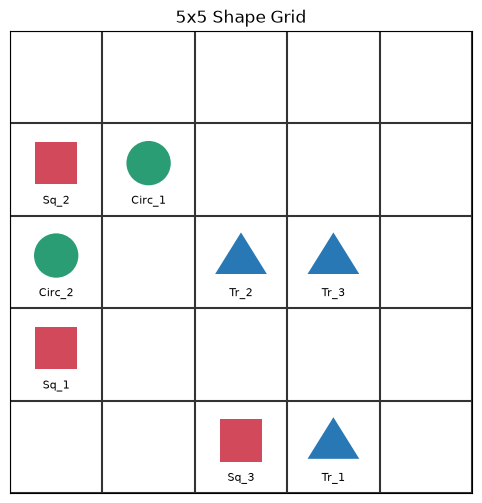

None

In [ ]:
def display_world(number_of_shapes=25):
    # Change this value to set the maximum number of shapes allowed.
    total_shapes_allowed = 25 # Stays const.

    # A 5x5 grid has 25 spaces.
    if number_of_shapes < 0 or number_of_shapes > total_shapes_allowed:
        raise ValueError(
            f"number_of_shapes must be between 0 and {total_shapes_allowed}"
        )

    shape_types = ["Tr", "Sq", "Circ"]
    shapes_to_place = []

    # Add the shape types in order so their counts stay nearly equal.
    for number in range(number_of_shapes):
        shape = shape_types[number % 3]
        shapes_to_place.append(shape)

    # Shuffle the shapes and grid spaces so the layout is different each time.
    random.shuffle(shapes_to_place)
    grid_spaces = list(range(total_shapes_allowed))
    random.shuffle(grid_spaces)
    chosen_spaces = grid_spaces[:number_of_shapes]

    shape_colors = {
        "Tr": "#2878B5",
        "Sq": "#D1495B",
        "Circ": "#2A9D75",
    }
    shape_counts = {"Tr": 0, "Sq": 0, "Circ": 0}

    # Set up the empty 5x5 grid.
    _, axes = plt.subplots(figsize=(6, 6))
    axes.set_xlim(0, 5)
    axes.set_ylim(5, 0)
    axes.set_aspect("equal")
    axes.set_xticks(range(6))
    axes.set_yticks(range(6))
    axes.set_xticklabels([])
    axes.set_yticklabels([])
    axes.tick_params(length=0)
    axes.grid(True, linewidth=1.5, color="#333333")

    # Draw each shape and give it a number within its shape type.
    for index in range(number_of_shapes):
        space = chosen_spaces[index]
        shape = shapes_to_place[index]

        row = space // 5
        column = space % 5
        center_x = column + 0.5
        center_y = row + 0.43

        shape_counts[shape] = shape_counts[shape] + 1
        shape_number = shape_counts[shape]

        if shape == "Tr":
            triangle_points = [
                (center_x, center_y - 0.25),
                (center_x - 0.28, center_y + 0.2),
                (center_x + 0.28, center_y + 0.2),
            ]
            patch = Polygon(
                triangle_points,
                closed=True,
                facecolor=shape_colors[shape],
            )
        elif shape == "Sq":
            square_corner = (center_x - 0.23, center_y - 0.23)
            patch = Rectangle(
                square_corner,
                0.46,
                0.46,
                facecolor=shape_colors[shape],
            )
        else:
            patch = Circle(
                (center_x, center_y),
                0.24,
                facecolor=shape_colors[shape],
            )

        axes.add_patch(patch)
        axes.text(
            center_x,
            row + 0.84,
            f"{shape}_{shape_number}",
            ha="center",
            va="center",
            fontsize=8,
        )
    
    axes.set_title("5x5 Shape Grid")
    plt.show()


display(display_world(8))